# Отмена бронирований отелей

Задача: определить, будет ли отменено бронирование. Такой прогноз может помочь отелю оценить риск незаполненных номеров.

Данные: [Hotel Booking Demand на Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand). 119 390 бронирований двух отелей Португалии за 2015–2017 годы. Целевая переменная `is_canceled`: 1 означает отмену.

Источник: Nuno Antonio, Ana de Almeida, Luis Nunes, [Hotel booking demand datasets](https://doi.org/10.1016/j.dib.2018.11.126), 2019, CC BY 4.0.

Данные представляют исторические снимки бронирований, а не журнал событий. Работа оценивает качество на этих снимках. Она не доказывает возможность получить тот же результат в момент создания новой брони.

In [1]:
import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
    PrecisionRecallDisplay, roc_auc_score
)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})

## 1. Проверка данных

In [2]:
data = pd.read_csv("data/hotel_bookings.csv")
print("Размер:", data.shape)
print("Полных повторов:", data.duplicated().sum())
print(f"Доля отмен: {data['is_canceled'].mean():.1%}")
data.head()

Размер: (119390, 32)
Полных повторов: 31994
Доля отмен: 37.0%


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
data.isna().sum().loc[lambda values: values > 0].to_frame("Пропуски")

,Пропуски
children,4
country,488
agent,16340
company,112593


Совпадающие строки могут относиться к разным бронированиям: идентификаторы гостей удалены. Для этой работы оставляю по одной полной копии строки. Это меняет состав выборки, поэтому итоговые метрики относятся к очищенным данным. Пропуски заполняются внутри Pipeline после разделения выборок.

In [4]:
data = data.drop_duplicates().copy()
months = ["January", "February", "March", "April", "May", "June",
          "July", "August", "September", "October", "November", "December"]
data["arrival_month"] = data["arrival_date_month"].map(
    {month: number for number, month in enumerate(months, start=1)}
)
data["arrival_date"] = pd.to_datetime({
    "year": data["arrival_date_year"],
    "month": data["arrival_month"],
    "day": data["arrival_date_day_of_month"]
})
print("После удаления полных повторов:", data.shape[0])
print(f"Доля отмен: {data['is_canceled'].mean():.1%}")

После удаления полных повторов: 87396
Доля отмен: 27.5%


## 2. Разделение по времени и признаки

Обучение: 2015–2016 годы. Валидация: январь–апрель 2017. Тест: май–август 2017. Модель и порог выбираются только на валидации. Тест используется один раз после выбора.

Разделение по дате заезда проверяет перенос на более поздние бронирования. Это упрощённая временная проверка, без восстановления момента доступности каждой метки.

In [5]:
train = data[data["arrival_date"] < "2017-01-01"].copy()
valid = data[(data["arrival_date"] >= "2017-01-01") &
             (data["arrival_date"] < "2017-05-01")].copy()
test = data[data["arrival_date"] >= "2017-05-01"].copy()

pd.DataFrame([
    {"Выборка": name, "Строк": len(part), "Доля отмен": part["is_canceled"].mean(),
     "Начало": part["arrival_date"].min().date(), "Конец": part["arrival_date"].max().date()}
    for name, part in [("train", train), ("validation", valid), ("test", test)]
])

,Выборка,Строк,Доля отмен,Начало,Конец
0,train,55704,0.249749,2015-07-01,2016-12-31
1,validation,13956,0.283964,2017-01-01,2017-04-30
2,test,17736,0.346752,2017-05-01,2017-08-31


`reservation_status` и `reservation_status_date` исключены: они содержат итог бронирования. Не использую назначенный номер, число изменений, ожидание, оплату и ADR: эти значения могли обновляться после создания брони. Идентификаторы агентства и компании также исключены. Набор признаков задан явно.

In [6]:
categorical = ["hotel", "meal", "country", "market_segment",
               "distribution_channel", "reserved_room_type", "customer_type"]
numeric = ["lead_time", "arrival_month", "arrival_date_day_of_month",
           "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
           "babies", "is_repeated_guest", "previous_cancellations",
           "previous_bookings_not_canceled"]
features = categorical + numeric
X_train, y_train = train[features], train["is_canceled"]
X_valid, y_valid = valid[features], valid["is_canceled"]
X_test, y_test = test[features], test["is_canceled"]

## 3. Краткий анализ обучающей выборки

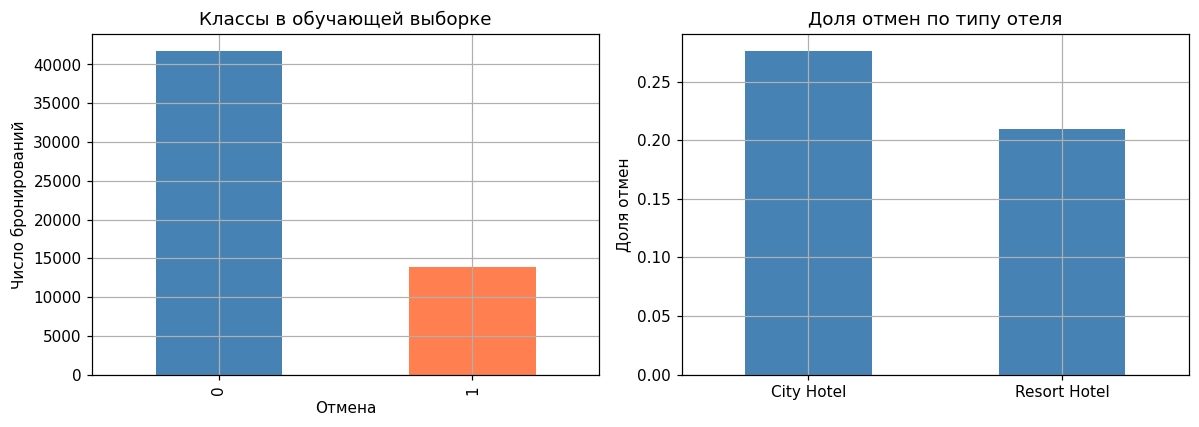

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train["is_canceled"].value_counts().sort_index().plot.bar(ax=axes[0], color=["steelblue", "coral"])
axes[0].set(title="Классы в обучающей выборке", xlabel="Отмена", ylabel="Число бронирований")
train.groupby("hotel")["is_canceled"].mean().plot.bar(ax=axes[1], color="steelblue", rot=0)
axes[1].set(title="Доля отмен по типу отеля", xlabel="", ylabel="Доля отмен")
plt.tight_layout()
plt.show()

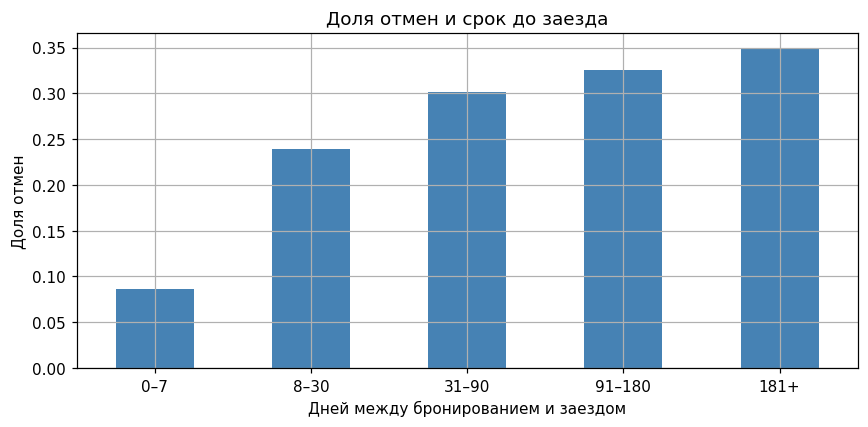

In [8]:
groups = pd.cut(train["lead_time"], [-1, 7, 30, 90, 180, np.inf],
                labels=["0–7", "8–30", "31–90", "91–180", "181+"])
train.groupby(groups, observed=True)["is_canceled"].mean().plot.bar(color="steelblue", rot=0)
plt.title("Доля отмен и срок до заезда")
plt.xlabel("Дней между бронированием и заездом")
plt.ylabel("Доля отмен")
plt.tight_layout()
plt.show()

Графики показывают связи в данных, а не причины отмены. Основная метрика сравнения моделей: Average Precision (AP), которая оценивает ранжирование положительного класса по precision и recall. Дополнительно считаю ROC-AUC и F1. Одной accuracy недостаточно: классы распределены неравномерно.

## 4. Обучение и эксперименты MLflow

Сравниваю константный прогноз, логистическую регрессию и два варианта бустинга. Для логистической регрессии использую One-Hot Encoding и масштабирование. Для бустинга категории кодируются числами и явно отмечаются как категориальные. Все преобразования обучаются только на train.

In [9]:
def make_model(classifier):
    if isinstance(classifier, HistGradientBoostingClassifier):
        encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)
    else:
        encoder = OneHotEncoder(handle_unknown="ignore")
    preprocessing = ColumnTransformer([
        ("categories", make_pipeline(SimpleImputer(strategy="most_frequent"), encoder), categorical),
        ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric)
    ])
    return Pipeline([("preprocessing", preprocessing), ("classifier", classifier)])

models = {
    "dummy": DummyClassifier(strategy="prior"),
    "logistic": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "boosting_15": HistGradientBoostingClassifier(
        max_iter=150, max_leaf_nodes=15, learning_rate=0.1, l2_regularization=1.0,
        categorical_features=list(range(len(categorical))), early_stopping=False, random_state=42
    ),
    "boosting_31": HistGradientBoostingClassifier(
        max_iter=150, max_leaf_nodes=31, learning_rate=0.1, l2_regularization=1.0,
        categorical_features=list(range(len(categorical))), early_stopping=False, random_state=42
    )
}

In [10]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("hotel_cancellations")
results = []
fitted_models = {}
run_ids = {}

for name, classifier in models.items():
    with mlflow.start_run(run_name=name) as run:
        model = make_model(classifier)
        model.fit(X_train, y_train)
        probability = model.predict_proba(X_valid)[:, 1]
        metrics = {
            "valid_ap": average_precision_score(y_valid, probability),
            "valid_roc_auc": roc_auc_score(y_valid, probability),
            "valid_f1": f1_score(y_valid, probability >= 0.5, zero_division=0)
        }
        mlflow.log_params(classifier.get_params())
        mlflow.log_params({"train_end": "2016-12-31", "valid_end": "2017-04-30",
                           "train_rows": len(train), "valid_rows": len(valid)})
        mlflow.log_metrics(metrics)
        mlflow.log_dict({"features": features}, "features.json")
        mlflow.sklearn.log_model(model, name="model", input_example=X_train.head(3))
        fitted_models[name] = model
        run_ids[name] = run.info.run_id
        results.append({"model": name, **metrics})
        print(f"{name}: AP={metrics['valid_ap']:.4f}, ROC-AUC={metrics['valid_roc_auc']:.4f}")

results = pd.DataFrame(results).sort_values("valid_ap", ascending=False)
results.round(4)

dummy: AP=0.2840, ROC-AUC=0.5000
logistic: AP=0.5458, ROC-AUC=0.7618
boosting_15: AP=0.5869, ROC-AUC=0.7887
boosting_31: AP=0.5794, ROC-AUC=0.7793


,model,valid_ap,valid_roc_auc,valid_f1
2,boosting_15,0.5869,0.7887,0.4044
3,boosting_31,0.5794,0.7793,0.3977
1,logistic,0.5458,0.7618,0.3277
0,dummy,0.2840,0.5000,0.0000


## 5. Выбор порога

Выбираю модель по AP на валидации. Затем выбираю порог по F1 на той же валидации. F1 даёт компромисс между пропущенными отменами и ложными тревогами. Это учебный критерий: без стоимости ошибок нельзя назвать порог экономически оптимальным.

Выбранная модель: boosting_15
Порог: 0.15


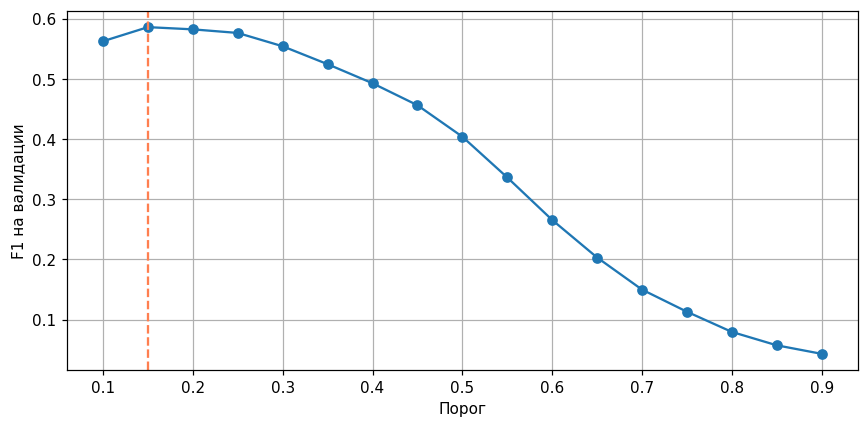

In [11]:
best_name = results.iloc[0]["model"]
best_model = fitted_models[best_name]
valid_probability = best_model.predict_proba(X_valid)[:, 1]
thresholds = np.arange(0.1, 0.91, 0.05)
f1_values = [f1_score(y_valid, valid_probability >= value) for value in thresholds]
threshold = float(thresholds[np.argmax(f1_values)])
print("Выбранная модель:", best_name)
print(f"Порог: {threshold:.2f}")
plt.plot(thresholds, f1_values, marker="o")
plt.axvline(threshold, color="coral", linestyle="--")
plt.xlabel("Порог")
plt.ylabel("F1 на валидации")
plt.tight_layout()
plt.show()

## 6. Итоговая оценка на тесте

После выбора модели и порога ничего не подстраиваю под тест. Сохраняется именно оценённая модель, без дополнительного переобучения.

test_ap           0.6045
test_roc_auc      0.7603
test_accuracy     0.6180
test_precision    0.4728
test_recall       0.8841
test_f1           0.6161
              precision    recall  f1-score   support

  Без отмены      0.886     0.477     0.620     11586
      Отмена      0.473     0.884     0.616      6150

    accuracy                          0.618     17736
   macro avg      0.679     0.680     0.618     17736
weighted avg      0.742     0.618     0.619     17736



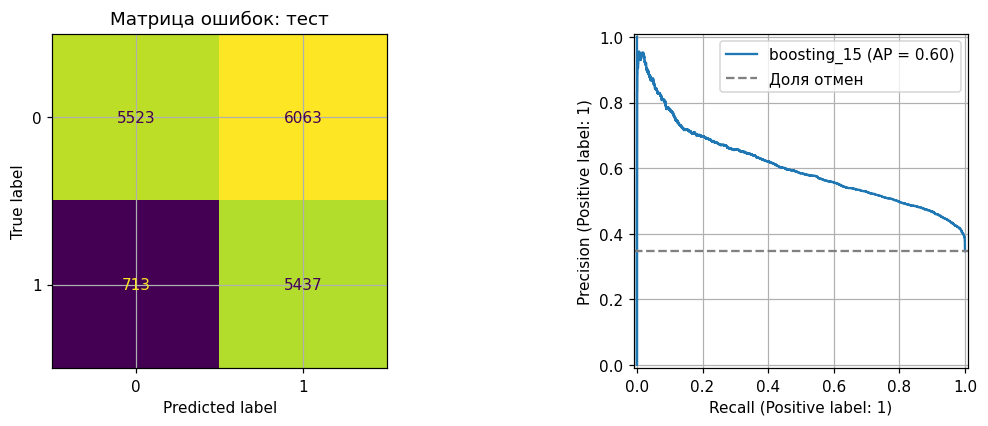

In [12]:
test_probability = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probability >= threshold).astype(int)
test_metrics = {
    "test_ap": average_precision_score(y_test, test_probability),
    "test_roc_auc": roc_auc_score(y_test, test_probability),
    "test_accuracy": accuracy_score(y_test, test_predictions),
    "test_precision": precision_score(y_test, test_predictions),
    "test_recall": recall_score(y_test, test_predictions),
    "test_f1": f1_score(y_test, test_predictions)
}
print(pd.Series(test_metrics).round(4).to_string())
print(classification_report(y_test, test_predictions, target_names=["Без отмены", "Отмена"], digits=3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, ax=axes[0], colorbar=False)
axes[0].set_title("Матрица ошибок: тест")
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[1], name=best_name)
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", label="Доля отмен")
axes[1].legend()
plt.tight_layout()
plt.show()

In [13]:
errors = X_test.copy()
errors["actual"] = y_test
errors["predicted"] = test_predictions
errors["probability"] = test_probability
errors[errors["actual"] != errors["predicted"]][
    ["hotel", "lead_time", "country", "market_segment", "actual", "predicted", "probability"]
].head(10).round(3)

,hotel,lead_time,country,market_segment,actual,predicted,probability
11289,Resort Hotel,237,GBR,Online TA,1,0,0.072
11291,Resort Hotel,65,IRL,Online TA,1,0,0.146
11292,Resort Hotel,65,IRL,Direct,1,0,0.066
11293,Resort Hotel,208,GBR,Online TA,1,0,0.095
11294,Resort Hotel,155,GBR,Online TA,1,0,0.088
11295,Resort Hotel,13,ROU,Online TA,1,0,0.102
11296,Resort Hotel,152,FRA,Online TA,1,0,0.123
11298,Resort Hotel,155,GBR,Online TA,1,0,0.095
11299,Resort Hotel,73,GBR,Online TA,1,0,0.145
11304,Resort Hotel,111,IRL,Online TA,1,0,0.122


## 7. Сохранение модели

В файл входят Pipeline и выбранный порог. Контейнер загружает этот файл и получает исходные признаки из CSV.

In [14]:
joblib.dump({"model": best_model, "threshold": threshold}, "model.joblib", compress=3)
X_test.head(5).to_csv("example.csv", index=False)
with mlflow.start_run(run_id=run_ids[best_name]):
    mlflow.log_param("threshold", threshold)
    mlflow.log_metrics(test_metrics)
    mlflow.log_artifact("model.joblib")
    mlflow.log_artifact("example.csv")
print("Сохранены model.joblib и example.csv")

Сохранены model.joblib и example.csv


## Вывод

На валидации лучший результат показал бустинг с 15 листьями: AP = 0.587 против 0.546 у логистической регрессии и 0.284 у константной модели. Более сложный бустинг с 31 листом оказался немного хуже.

На тесте получены AP = 0.605, ROC-AUC = 0.760 и F1 = 0.616. Выбранный на валидации порог 0.15 позволяет найти 5437 из 6150 отмен (recall = 88.4%). Пропущено 713 отмен. При этом возникло 6063 ложных тревоги, поэтому precision составляет только 47.3%.

Accuracy = 61.8% ниже, чем у прогноза «отмены не будет» для всех строк (65.3%). Такой постоянный прогноз вообще не находит отмены. Здесь низкий порог повышает полноту за счёт ложных тревог. Модель можно рассматривать как способ выделить бронирования для дополнительной проверки, но не как основание автоматически отменять бронь или продавать занятый номер.

Ограничения: два отеля, исторические данные и отсутствие идентификаторов гостей. Один гость мог попасть в разные периоды. Удаление повторов меняет выборку. Вероятности не проверялись на калибровку. Результат нельзя автоматически переносить на другой отель или считать прогнозом в момент создания брони.